Optimization terminated successfully.
         Current function value: 0.666683
         Iterations 6


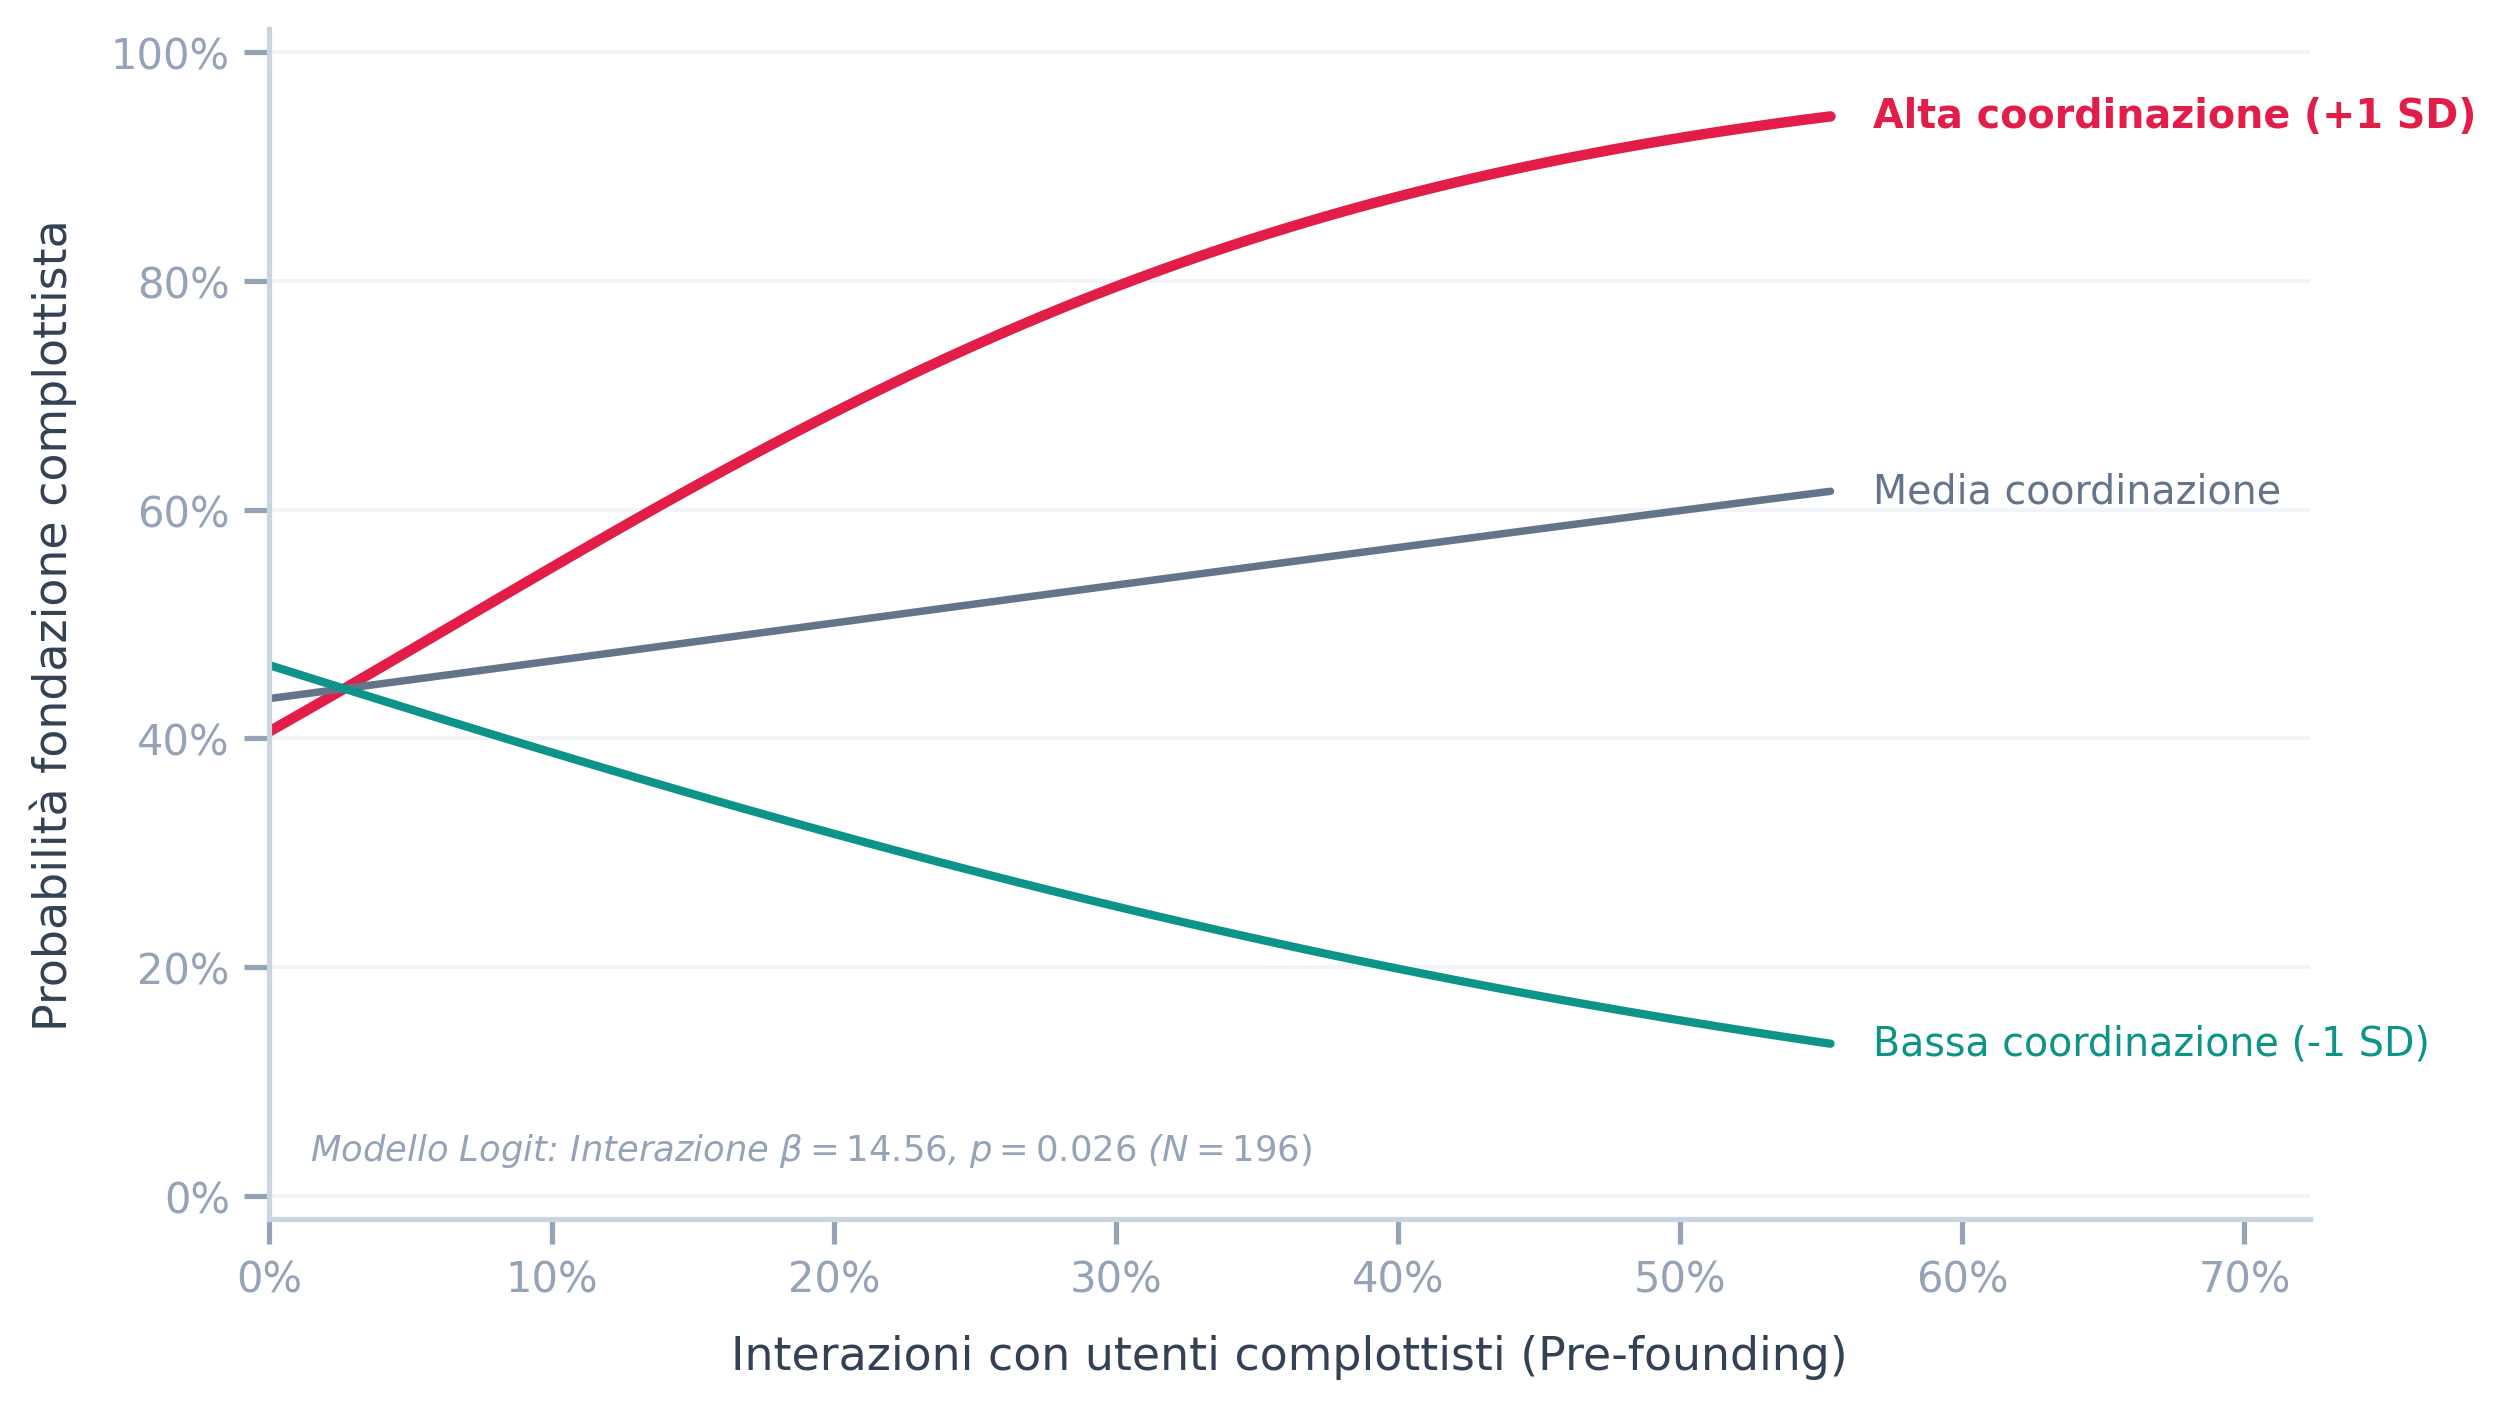

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="ticks")
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "font.family": "sans-serif",
        "font.sans-serif": ["DejaVu Sans", "Helvetica", "Arial"],
        "font.size": 10,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "text.color": "#334155",
        "axes.labelcolor": "#334155",
        "xtick.color": "#94A3B8",
        "ytick.color": "#94A3B8",
    }
)


DATASET_PATH = "../data/processed/dataset.csv"
df = pd.read_csv(DATASET_PATH)

var_x = "ratio_interactions_cc"
var_m = "avg_linguistic_coordination_cc"
var_y = "is_anchor"

df["target_binary"] = df[var_y].astype(int)
sub_df = df.dropna(subset=[var_x, var_m, "target_binary"]).copy()


mean_x = sub_df[var_x].mean()
mean_m = sub_df[var_m].mean()
std_m = sub_df[var_m].std()

sub_df["x_c"] = sub_df[var_x] - mean_x
sub_df["m_c"] = sub_df[var_m] - mean_m


logit_model = smf.logit("target_binary ~ x_c * m_c", data=sub_df).fit()


coef_inter = logit_model.params["x_c:m_c"]
p_inter = logit_model.pvalues["x_c:m_c"]


levels = [
    {
        "name": "Alta coordinazione (+1 SD)",
        "val": mean_m + std_m,
        "color": "#E11D48", 
        "lw": 2.5,
    },
    {
        "name": "Media coordinazione",
        "val": mean_m,
        "color": "#64748B",  
        "lw": 1.8,
    },
    {
        "name": "Bassa coordinazione (-1 SD)",
        "val": mean_m - std_m,
        "color": "#0D9488",  
        "lw": 2.0,
    },
]

x_max = min(0.60, float(sub_df[var_x].quantile(0.98)))
x_vals = np.linspace(0, x_max, 120)


fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=300)


ax.grid(axis="y", color="#F1F5F9", linestyle="-", linewidth=1.0)
ax.set_axisbelow(True)


for lvl in levels:
    grid_df = pd.DataFrame(
        {"x_c": x_vals - mean_x, "m_c": lvl["val"] - mean_m}
    )
    preds = logit_model.predict(grid_df)

    ax.plot(x_vals, preds, color=lvl["color"], linewidth=lvl["lw"])


    final_y = preds.iloc[-1]
    ax.text(
        x_max + 0.015,
        final_y,
        lvl["name"],
        color=lvl["color"],
        fontsize=9.5,
        weight="semibold" if "Alta" in lvl["name"] else "normal",
        va="center",
    )


sns.despine(top=True, right=True, left=False, bottom=False)
ax.spines["left"].set_color("#CBD5E1")
ax.spines["bottom"].set_color("#CBD5E1")


ax.set_xlim(0, x_max + 0.17)
ax.set_ylim(-0.02, 1.02)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))


ax.set_xlabel("Interazioni con utenti complottisti (Pre-founding)", labelpad=8)
ax.set_ylabel("Probabilità fondazione complottista", labelpad=8)


ax.text(
    0.02,
    0.05,
    f"Modello Logit: Interazione $\\beta = {coef_inter:.2f}$, $p = {p_inter:.3f}$ ($N = {len(sub_df)})$",
    transform=ax.transAxes,
    fontsize=8.5,
    color="#94A3B8",
    style="italic",
)

plt.tight_layout()
plt.savefig("slide_moderation_statsmodels.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 11.3/11.3 MB 70.1 MB/s  0:00:00

   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------- ----------------------------- 1/4 [interface-meta]
   -------------------- ------------------- 2/4 [formulaic]
   -------------------- ------------------- 2/4 [formulaic]
   -------------------- ------------------- 2/4 [formulaic]
   -------------------- ------------------- 2/4 [formulaic]
   -------------------- ------------------- 2/4 [formulaic]
   -------------------- ------------------- 2/4 [formulaic]
   ------------------------------ --------- 3/4 [statsmodels]
   ------------------------------ --------- 3/4 [statsmodels]
   ------------------------------ --------- 3/4 [statsmodels]
   ------------------------------ --------- 3/4 [statsmodels]
   ---------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

sub_df["x_c"] = sub_df[var_x] - sub_df[var_x].mean()
sub_df["m_c"] = sub_df[var_m] - sub_df[var_m].mean()


model = smf.logit("target_binary ~ x_c * m_c", data=sub_df).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.666683
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:          target_binary   No. Observations:                  196
Model:                          Logit   Df Residuals:                      192
Method:                           MLE   Df Model:                            3
Date:                Mon, 28 Sep 2026   Pseudo R-squ.:                 0.03818
Time:                        14:56:58   Log-Likelihood:                -130.67
converged:                       True   LL-Null:                       -135.86
Covariance Type:            nonrobust   LLR p-value:                   0.01564
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0343      0.147     -0.233      0.816      -0.323       0.254
x_c            1.3279      1.